# 3) Thermodynamics of the SCO Transition

This notebook inspects the SCOPE Systems and retrieves the electronic and vibrational enthalpy and entropy terms to compute T1/2

**Important:** Notebooks must be executed in order. You're expected to run notebooks 0, 1 and 2 first.

In [1]:
import csv
import os
import sys

import numpy as np
import scope

sys.path.insert(0, os.path.abspath('..'))
from atlas_functions import (
    as_float, build_vibrational_bin_rows, filter_rows,
    mean_vibrational_bin_values, plot_frequency_contributions,
    plot_hs_ls_frequency_profiles, read_csv,
)

import matplotlib.pyplot as plt

## User Configuration

In [ ]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                    # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/"  # Update with your path 
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy" # Update with your path
save_figures  = True

# Figures Path
if save_figures: figures_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/"       # Update with your path
else:            figures_path = None 

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
analysis_path = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
outputs_path  = analysis_path + "Outputs/"

# Checks Scope Version
expected_scope_version = "0.9.6"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(f"This analysis requires SCOPE {expected_scope_version}; the active environment provides {installed_scope_version!r}.")

# This folders are required, together with the system-dedicated folders inside
required_data_paths = [data_path + "2-Systems/", data_path + "3-Computations/"]
missing_paths       = [path for path in required_data_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS data directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
os.makedirs(outputs_path, exist_ok=True)

# Loads Environment
env = scope.load_binary(env_path)

print(f"SCOPE version:      {installed_scope_version}")
print(f"Data directory:     {data_path}")
print(f"SCOPE environment:  {env_path}")
print(f"Analysis outputs:   {outputs_path}")
print(f"Manuscript Figures: {figures_path}")

SCOPE version:      0.9.6
Data directory:     /Users/sergivela/Documents/SCOPE/Database_SCO/Data/
SCOPE environment:  /Users/sergivela/Documents/SCOPE/Database_SCO/Data/scope_env_atlas.npy
Analysis outputs:   /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/
Manuscript Figures: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/


### Database

In [3]:
# Loads finished systems that are "unique" (i.e. non-repeated)
unique_csv_path     = outputs_path + "unique_systems.csv"

unique_systems = []
with open(unique_csv_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        sys = scope.load_binary(f"{data_path}/{row['path']}")
        sys.set_paths_from_environment(env)
        unique_systems.append(sys)

print(f"{len(unique_systems)} Unique systems loaded")

602 Unique systems loaded


## Prepares Thermodynamic Data for all Unique Systems

In [4]:
thermo_unique_path = outputs_path + "unique_thermodynamic_data.csv"
thermo_unique_line = [] # For Storage
dHelecs = []            # For easy access to values
dHvibs  = [] 
dSvibs  = [] 
dSelecs = [] 
dGtots  = [] 
T12s    = []

for sys in unique_systems:
    exists, this_branch = sys.find_branch('isolated')
    relative_path       = f"2-Systems/{sys.refcode}/{sys.refcode}.npy"

    # dHelec
    if 'dHelec' in this_branch.results.keys(): 
        dHelec = this_branch.results["dHelec"].value*scope.constants.har2kJmol
    else:
        dHelec = None
    dHelecs.append(float(dHelec))

    # dHvib
    if 'dHvib' in this_branch.results.keys(): 
        dHvib = this_branch.results["dHvib"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol
    else:
        dHvib = None
    dHvibs.append(float(dHvib))

    # dSvib
    if 'dSvib' in this_branch.results.keys(): 
        dSvib = this_branch.results["dSvib"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol*298
    else:
        dSvib = None
    dSvibs.append(float(dSvib))

    # dSelec
    if 'dSelec' in this_branch.results.keys(): 
        dSelec = this_branch.results["dSelec"].value*scope.constants.har2kJmol*298
    else:
        dSelec = None
    dSelecs.append(float(dSelec))

    # dGtot
    if 'dGtot' in this_branch.results.keys(): 
        dGtot = this_branch.results["dGtot"].find_value_with_property("temperature", 298).value*scope.constants.har2kJmol
    else:
        dGtot = None
    dGtots.append(float(dGtot))

    # T12
    if 'T12' in this_branch.results.keys(): 
        T12 = this_branch.results["T12"].value
        if T12 is None:   T12 = "None"
        elif T12 == "":   T12 = "None"
    else:
        T12 = "None"
    T12s.append(T12)

    # Denticity
    found, mol = sys.find_source("ref_hs_mol")
    if found:
        ligands = mol.ligands
        assert ligands is not None, f"Ligands not found in the reference molecule of {sys.refcode}."
        if all(lig.__eq__(ligands[0], with_graph=False) for lig in ligands):
            homoleptic = True
            if ligands[0].get_denticity()==1:    dent = int(1) 
            elif ligands[0].get_denticity()==2:  dent = int(2)
            elif ligands[0].get_denticity()==3:  dent = int(3)
            elif ligands[0].get_denticity()==6:  dent = int(6)
        else:
            homoleptic = False
            dent = "unknown"
    else:
        print(f"Reference molecule not found for {sys.refcode}. Cannot determine homolepticity or denticity.")
        homoleptic = "unknown"
        dent = "unknown"

    thermo_unique_line.append({"refcode": sys.refcode_wo_digits, "path": relative_path, "status": "finished", "dHelec[kJ/mol]": np.round(dHelec,6), "dHvib[kJ/mol](T=298K)": np.round(dHvib,6), "dSvib·T[kJ/mol](T=298K)": np.round(dSvib,6), "dSelec·T[kJ/mol](T=298K)": np.round(dSelec,6), "dGtot[kJ/mol](T=298K)": np.round(dGtot,6), "T12[K]": T12, "homoleptic": homoleptic, "denticity": dent}) 

with open(thermo_unique_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["refcode", "path", "status", "dHelec[kJ/mol]", "dHvib[kJ/mol](T=298K)", "dSvib·T[kJ/mol](T=298K)", "dSelec·T[kJ/mol](T=298K)", "dGtot[kJ/mol](T=298K)", "T12[K]", "homoleptic", "denticity"])
    writer.writeheader()
    writer.writerows(thermo_unique_line)

print("Results stored in:", thermo_unique_path)


Results stored in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/unique_thermodynamic_data.csv


## Histograms

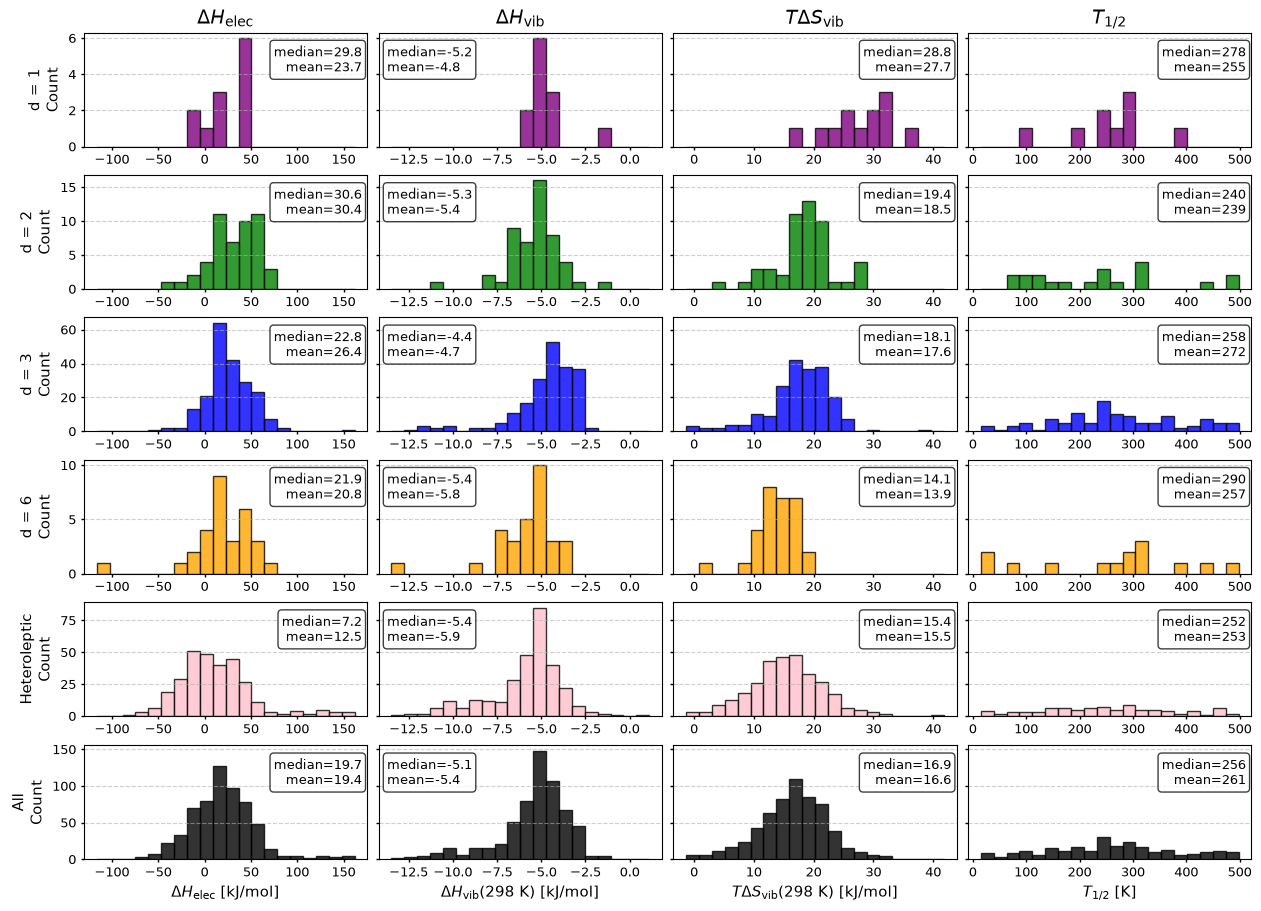

In [5]:
# Combined thermodynamic histograms by denticity

histogram_specs = [
    {
        "column": "dHelec[kJ/mol]",
        "xlabel": r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]",
        "title": r"$\Delta H_{\mathrm{elec}}$",
        "fmt": ".1f",
    },
    {
        "column": "dHvib[kJ/mol](T=298K)",
        "xlabel": r"$\Delta H_{\mathrm{vib}}$(298 K) [kJ/mol]",
        "title": r"$\Delta H_{\mathrm{vib}}$",
        "fmt": ".1f",
    },
    {
        "column": "dSvib·T[kJ/mol](T=298K)",
        "xlabel": r"$T\Delta S_{\mathrm{vib}}$(298 K) [kJ/mol]",
        "title": r"$T\Delta S_{\mathrm{vib}}$",
        "fmt": ".1f",
    },
    {
        "column": "T12[K]",
        "xlabel": r"$T_{1/2}$ [K]",
        "title": r"$T_{1/2}$",
        "fmt": ".0f",
        "filter": lambda row: row["T12[K]"] != "None",
    },
]

denticity_specs = [
    ("1", "d = 1", "purple"),
    ("2", "d = 2", "green"),
    ("3", "d = 3", "blue"),
    ("6", "d = 6", "orange"),
    ("unknown", "Heteroleptic", "pink"),
    ("all", "All", "black"),
]

nbins = 20
fig, axs = plt.subplots(
    len(denticity_specs), len(histogram_specs),
    figsize=(12.5, 9.0),
    constrained_layout=True,
    sharey="row",
)

for j, spec in enumerate(histogram_specs):
    rows = filter_rows(thermo_unique_path, spec.get("filter", lambda row: row[spec["column"]] != "None"))
    values_by_denticity = {
        denticity: [float(row[spec["column"]]) for row in rows if row["denticity"] == denticity]
        for denticity, _, _ in denticity_specs[:-1]
    }
    values_by_denticity["all"] = [
        value
        for denticity in values_by_denticity
        for value in values_by_denticity[denticity]
    ]

    to_plot = values_by_denticity["all"]
    xmin, xmax = min(to_plot), max(to_plot)
    if xmin == xmax:
        bins = [xmin - 0.5, xmax + 0.5]
    else:
        bin_width = (xmax - xmin) / nbins
        bins = [xmin + i * bin_width for i in range(nbins + 1)]

    for i, (denticity, row_label, color) in enumerate(denticity_specs):
        ax = axs[i, j]
        values = values_by_denticity[denticity]
        ax.hist(values, bins=bins, color=color, edgecolor="black", alpha=0.8)
        ax.tick_params(axis="both", which="major", length=2, width=1, direction="out", labelsize=9)
        ax.tick_params(axis="both", which="minor", length=1, width=1, direction="out")
        ax.grid(axis="y", linestyle="--", alpha=0.6)

        if j == 0:
            ax.set_ylabel(f"{row_label}\nCount", fontsize=11)
        if i == 0:
            ax.set_title(spec["title"], fontsize=14)
        if i == len(denticity_specs) - 1:
            ax.set_xlabel(spec["xlabel"], fontsize=11)

        if values:
            text_x = 0.03 if spec["column"] == "dHvib[kJ/mol](T=298K)" else 0.98
            text_ha = "left" if spec["column"] == "dHvib[kJ/mol](T=298K)" else "right"
            ax.text(
                text_x, 0.90,
                f"median={np.median(values):{spec['fmt']}}\n"
                f"mean={np.mean(values):{spec['fmt']}}",
                transform=ax.transAxes,
                ha=text_ha,
                va="top",
                fontsize=9,
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.75),
            )

fig.savefig(figures_path + "TD_histograms_denticity.png", dpi=400)
plt.show()



## Correlation between dHelec and T

### Data extraction and fitting

In [6]:
filtered = filter_rows(thermo_unique_path, lambda row: row["T12[K]"] != "None")
h1 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "1"]
h2 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "2"]
h3 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "3"]
h6 = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "6"]
ho = [float(row["dHelec[kJ/mol]"]) for row in filtered if row["denticity"] == "unknown"]
t1 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "1"]
t2 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "2"]
t3 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "3"]
t6 = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "6"]
to = [float(row["T12[K]"]) for row in filtered if row["denticity"] == "unknown"]

## Monodentate
coef1 = np.polyfit(h1, t1, 1)
x1_fit = np.linspace(min(h1), max(h1), 200)
y1_fit = coef1[0] * x1_fit + coef1[1]
r1 = 1 - np.sum((np.array(t1) - (coef1[0] * np.array(h1) + coef1[1])) ** 2) / np.sum((np.array(t1) - np.mean(t1)) ** 2)

## Bidentate
coef2  = np.polyfit(h2, t2, 1)
x2_fit = np.linspace(min(h2), max(h2), 200)
y2_fit = coef2[0] * x2_fit + coef2[1]
r2 = 1 - np.sum((np.array(t2) - (coef2[0] * np.array(h2) + coef2[1])) ** 2) / np.sum((np.array(t2) - np.mean(t2)) ** 2)

## Tridentate
coef3  = np.polyfit(h3, t3, 1)
x3_fit = np.linspace(min(h3), max(h3), 200)
y3_fit = coef3[0] * x3_fit + coef3[1]
r3 = 1 - np.sum((np.array(t3) - (coef3[0] * np.array(h3) + coef3[1])) ** 2) / np.sum((np.array(t3) - np.mean(t3)) ** 2)

## Hexadentate
coef6  = np.polyfit(h6, t6, 1)
x6_fit = np.linspace(min(h6), max(h6), 200)
y6_fit = coef6[0] * x6_fit + coef6[1]
r6 = 1 - np.sum((np.array(t6) - (coef6[0] * np.array(h6) + coef6[1])) ** 2) / np.sum((np.array(t6) - np.mean(t6)) ** 2)

## Heteroleptic
coefo  = np.polyfit(ho, to, 1)
xo_fit = np.linspace(min(ho), max(ho), 200)
yo_fit = coefo[0] * xo_fit + coefo[1]
ro = 1 - np.sum((np.array(to) - (coefo[0] * np.array(ho) + coefo[1])) ** 2) / np.sum((np.array(to) - np.mean(to)) ** 2)

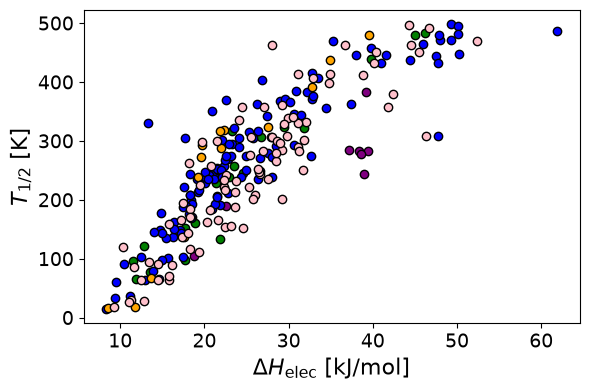

In [7]:
fig, ax = plt.subplots(figsize=(6, 4), tight_layout=True)
ax.scatter(h1, t1, color='purple', edgecolor='black')
ax.scatter(h2, t2, color='green', edgecolor='black')
ax.scatter(h3, t3, color='blue', edgecolor='black')
ax.scatter(h6, t6, color='orange', edgecolor='black')
ax.scatter(ho, to, color='pink', edgecolor='black')
ax.set_ylabel(r"$T_{1/2}$ [K]", fontsize=16)
ax.set_xlabel(r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]", fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=14)
fig.savefig(figures_path + "T12_vs_dHelec_denticity_data.png", dpi=400)

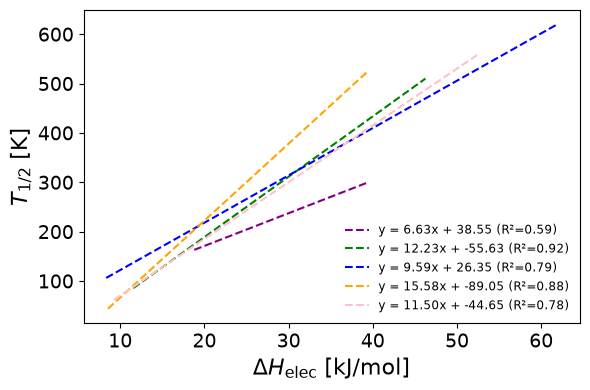

In [8]:
fig, ax = plt.subplots(figsize=(6, 4), tight_layout=True)
ax.plot(x1_fit, y1_fit, color='purple', linestyle='--', label=f'y = {coef1[0]:.2f}x + {coef1[1]:.2f} (R²={r1:.2f})')
ax.plot(x2_fit, y2_fit, color='green', linestyle='--',  label=f'y = {coef2[0]:.2f}x + {coef2[1]:.2f} (R²={r2:.2f})')
ax.plot(x3_fit, y3_fit, color='blue', linestyle='--',   label=f'y = {coef3[0]:.2f}x + {coef3[1]:.2f} (R²={r3:.2f})')
ax.plot(x6_fit, y6_fit, color='orange', linestyle='--', label=f'y = {coef6[0]:.2f}x + {coef6[1]:.2f} (R²={r6:.2f})')
ax.plot(xo_fit, yo_fit, color='pink', linestyle='--',   label=f'y = {coefo[0]:.2f}x + {coefo[1]:.2f} (R²={ro:.2f})')
ax.set_ylabel(r"$T_{1/2}$ [K]", fontsize=16)
ax.set_xlabel(r"$\Delta H_{\mathrm{elec}}$ [kJ/mol]", fontsize=16)
#ax.set_ylim(0,600)
#ax.set_xlim(0,70)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.legend(frameon=False, fontsize=8.5)
#ax.legend(loc="upper left", fontsize=10, frameon=False)
fig.savefig(figures_path + "T12_vs_dHelec_denticity_fit.png", dpi=400)

## Values for SCO between 250 and 350 K

In [9]:
# Thermodynamic ranges compatible with a SCO transition between 250 and 350 K

sco_t12_min = 250.0
sco_t12_max = 350.0

thermo_columns = {
    "dHelec[kJ/mol]": "dHelec[kJ/mol]",
    "dHvib[kJ/mol]": "dHvib[kJ/mol](T=298K)",
    "T*dSvib[kJ/mol]": "dSvib·T[kJ/mol](T=298K)",
}

sco_rows = []
with open(thermo_unique_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        t12 = as_float(row.get("T12[K]"))
        if t12 is not None and sco_t12_min <= t12 <= sco_t12_max:
            sco_rows.append(row)

compatible_ranges = []
for label, column in thermo_columns.items():
    values = np.array([as_float(row[column]) for row in sco_rows], dtype=float)
    compatible_ranges.append({
        "quantity": label,
        "n": len(values),
        "min": round(np.min(values), 2),
        "max": round(np.max(values), 2),
        "p10": round(np.percentile(values, 10), 2),
        "p90": round(np.percentile(values, 90), 2),
        "median": round(np.median(values), 2),
    })

print(f"SCO-compatible window: {len(sco_rows)} systems with {sco_t12_min:.0f} <= T1/2 <= {sco_t12_max:.0f} K")
compatible_ranges


SCO-compatible window: 75 systems with 250 <= T1/2 <= 350 K


[{'quantity': 'dHelec[kJ/mol]',
  'n': 75,
  'min': np.float64(13.33),
  'max': np.float64(47.7),
  'p10': np.float64(21.46),
  'p90': np.float64(31.99),
  'median': np.float64(26.41)},
 {'quantity': 'dHvib[kJ/mol]',
  'n': 75,
  'min': np.float64(-8.65),
  'max': np.float64(1.1),
  'p10': np.float64(-6.25),
  'p90': np.float64(-2.94),
  'median': np.float64(-4.61)},
 {'quantity': 'T*dSvib[kJ/mol]',
  'n': 75,
  'min': np.float64(5.37),
  'max': np.float64(41.79),
  'p10': np.float64(13.12),
  'p90': np.float64(24.84),
  'median': np.float64(18.09)}]

# Frequency-Resolved Vibrational Contributions

The HS--LS vibrational entropy and enthalpy differences are decomposed into the same frequency windows at 298.15 K. Both quantities are evaluated with the SCOPE harmonic-oscillator functions, `get_Svib` and `get_Hvib`, using their default treatment of imaginary frequencies, and stored in a shared CSV cache.

In [10]:
TEMPERATURE = 298.15
FREQ_BINS_CM = np.array([1, 50, 100, 200, 400, 800, 1200, 1600, 4000], dtype=float)
DENTICITIES_TO_COMPARE = ['1', '2', '3', '6']
ENTROPY_METHOD = 'scope.thermodynamics.get_Svib(HO, imaginary=ignore; SCOPE 0.9.6 defaults)'
ENTHALPY_METHOD = 'scope.thermodynamics.get_Hvib(imaginary=ignore; SCOPE 0.9.6 defaults)'

overwrite = True

In [11]:
vibrational_bins_path = outputs_path + 'unique_vibrational_data_bins.csv'
required_columns = {
    'refcode', 'denticity', 'homoleptic', 'HS_minimum_state', 'LS_minimum_state', 'temperature[K]',
    'entropy_method', 'enthalpy_method', 'bin_low[cm-1]', 'bin_high[cm-1]',
    'bin_label[cm-1]', 'HS_Svib[J·mol-1·K-1]', 'LS_Svib[J·mol-1·K-1]',
    'dSvib[J·mol-1·K-1]', 'HS_Hvib[kJ·mol-1]', 'LS_Hvib[kJ·mol-1]',
    'dHvib[kJ·mol-1]', 'HS_n_modes', 'LS_n_modes', 'd_n_modes',
    'HS_mode_fraction', 'LS_mode_fraction', 'd_mode_fraction',
    'HS_mean_S_per_mode[J·mol-1·K-1]', 'LS_mean_S_per_mode[J·mol-1·K-1]',
    'd_mean_S_per_mode[J·mol-1·K-1]',
}

thermo_by_refcode = {row.get('refcode', row.get('id')): row for row in read_csv(thermo_unique_path)}
expected_refcodes = set(thermo_by_refcode)
expected_bins = set(zip(FREQ_BINS_CM[:-1], FREQ_BINS_CM[1:]))

if os.path.exists(vibrational_bins_path) and not overwrite:
    vibrational_bin_rows = read_csv(vibrational_bins_path)
    cached_columns = set(vibrational_bin_rows[0]) if vibrational_bin_rows else set()
    cached_refcodes = {row['refcode'] for row in vibrational_bin_rows}
    if required_columns - cached_columns:
        print('The cached table is missing required columns; rebuilding it.')
        overwrite = True
    elif {(float(row['bin_low[cm-1]']), float(row['bin_high[cm-1]'])) for row in vibrational_bin_rows} != expected_bins:
        print('The cached table uses different frequency bins; rebuilding it.')
        overwrite = True
    elif cached_refcodes != expected_refcodes:
        print('The cached table does not match the current unique-system set; rebuilding it.')
        overwrite = True
    elif any(
        row['entropy_method'] != ENTROPY_METHOD or row['enthalpy_method'] != ENTHALPY_METHOD
        for row in vibrational_bin_rows
    ):
        print('The cached table uses different thermochemistry settings; rebuilding it.')
        overwrite = True
    else:
        print(f'Loaded {len(vibrational_bin_rows)} frequency-bin rows from {vibrational_bins_path}')

if overwrite or not os.path.exists(vibrational_bins_path):
    vibrational_bin_rows, failures = build_vibrational_bin_rows(
        unique_systems, thermo_by_refcode, TEMPERATURE, FREQ_BINS_CM,
        ENTROPY_METHOD, ENTHALPY_METHOD,
    )

    with open(vibrational_bins_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(vibrational_bin_rows[0]))
        writer.writeheader()
        writer.writerows(vibrational_bin_rows)
    print(f'Wrote {len(vibrational_bin_rows)} frequency-bin rows to {vibrational_bins_path}')
    print(f'Failures: {len(failures)}')
    if failures:
        print(failures[:10])

Wrote 4816 frequency-bin rows to /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/unique_vibrational_data_bins.csv
Failures: 0


In [12]:
# FEPHAK is excluded because its ligand-composition descriptor cannot be generated.
homoleptic_bin_rows = [
    row for row in vibrational_bin_rows
    if str(row['homoleptic']).lower() == 'true'
    and str(row['denticity']) in DENTICITIES_TO_COMPARE
    and row['refcode'] != 'FEPHAK'
]
bin_order = [f'{int(low)}-{int(high)}' for low, high in zip(FREQ_BINS_CM[:-1], FREQ_BINS_CM[1:])]

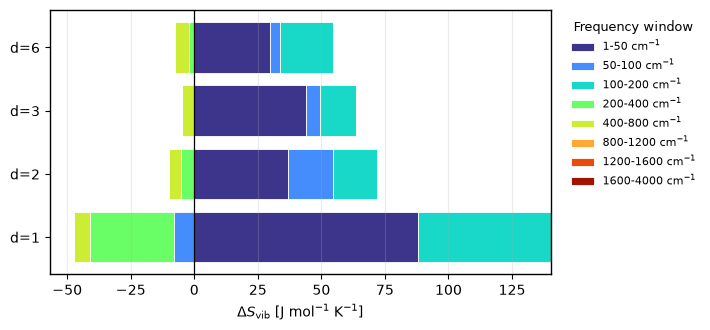

(<Figure size 720x340 with 1 Axes>,
 <Axes: xlabel='$\\Delta S_{\\mathrm{vib}}$ [J mol$^{-1}$ K$^{-1}$]'>)

In [13]:
dSvib_values, ordered = mean_vibrational_bin_values(homoleptic_bin_rows, 'dSvib[J·mol-1·K-1]', DENTICITIES_TO_COMPARE, bin_order)
plot_frequency_contributions(dSvib_values, ordered, bin_order, r'$\Delta S_{\mathrm{vib}}$ [J mol$^{-1}$ K$^{-1}$]', os.path.join(figures_path, 'dSvib_binned_contribution.png') if figures_path else None)

**Caption.** Mean frequency-resolved contribution to $Delta S_{mathrm{vib}}$ for each denticity. Each horizontal bar decomposes the average HS--LS vibrational entropy change into frequency windows; positive segments indicate regions where the HS state contributes more entropy than the LS state.

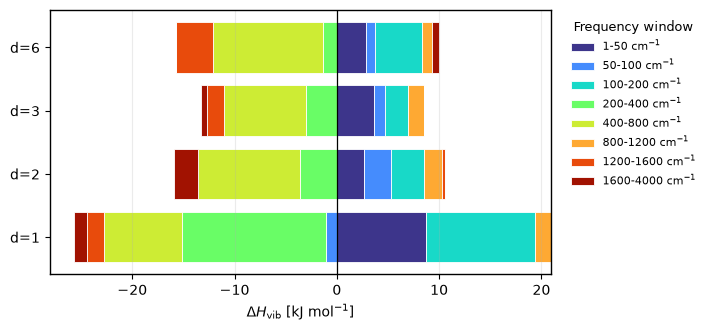

(<Figure size 720x340 with 1 Axes>,
 <Axes: xlabel='$\\Delta H_{\\mathrm{vib}}$ [kJ mol$^{-1}$]'>)

In [14]:
dHvib_values, ordered = mean_vibrational_bin_values(
    homoleptic_bin_rows, 'dHvib[kJ·mol-1]', DENTICITIES_TO_COMPARE, bin_order
)
plot_frequency_contributions(
    dHvib_values, ordered, bin_order,
    r'$\Delta H_{\mathrm{vib}}$ [kJ mol$^{-1}$]',
    os.path.join(figures_path, 'dHvib_binned_contribution.png') if figures_path else None,
)

**Caption.** Mean frequency-resolved contribution to $Delta H_{mathrm{vib}}$ for each denticity, using the same frequency windows as the entropy decomposition. Positive and negative segments indicate frequency regions that respectively increase or decrease the HS--LS vibrational enthalpy difference.

## Mode Populations and Entropic Weight per Mode (discarded)

The frequency-resolved entropy difference can arise because a spin state places a larger fraction of its positive vibrational modes in a given window, because those modes carry more entropy individually, or through both effects. For every system and frequency window, the analysis therefore records the positive-mode count, its fraction of all positive modes covered by the configured bins, and $S_{\mathrm{vib}}/N$ for the modes in that window. Raw counts are retained in `unique_vibrational_data_bins.csv`; the normalized fractions below remove the leading dependence on molecular size.

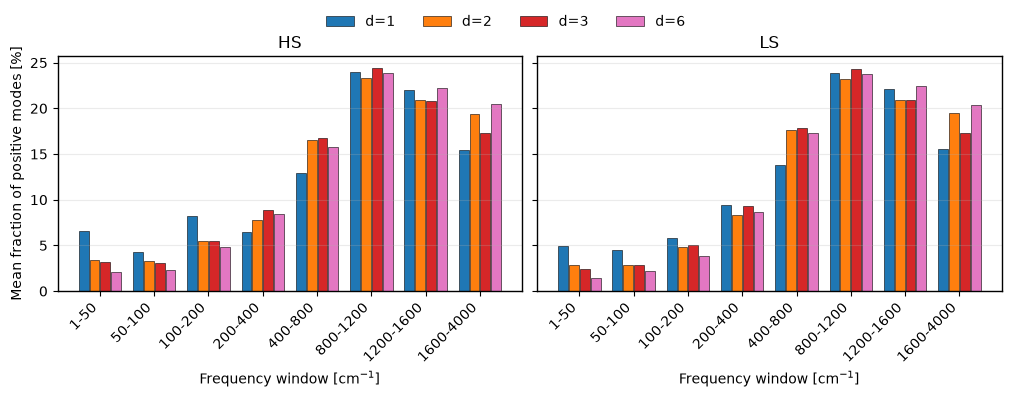

(<Figure size 1000x360 with 2 Axes>,
 array([<Axes: title={'center': 'HS'}, xlabel='Frequency window [cm$^{-1}$]', ylabel='Mean fraction of positive modes [%]'>,
        <Axes: title={'center': 'LS'}, xlabel='Frequency window [cm$^{-1}$]'>],
       dtype=object))

In [15]:
hs_mode_fractions, ordered = mean_vibrational_bin_values(homoleptic_bin_rows, 'HS_mode_fraction', DENTICITIES_TO_COMPARE, bin_order)
ls_mode_fractions, _ = mean_vibrational_bin_values(homoleptic_bin_rows, 'LS_mode_fraction', ordered, bin_order)
plot_hs_ls_frequency_profiles(100 * hs_mode_fractions, 100 * ls_mode_fractions, ordered, bin_order, 'Mean fraction of positive modes [%]', os.path.join(figures_path, 'vibrational_mode_fractions.png') if figures_path else None)

**Caption.** Mean distribution of the analyzed positive vibrational modes across frequency windows for each denticity, shown separately for the HS and LS states. Fractions are calculated per complex before averaging, so each complex contributes equally irrespective of molecular size. Enrichment of the HS distribution at low frequency relative to the LS distribution identifies a mode-population contribution to $\Delta S_{\mathrm{vib}}$.

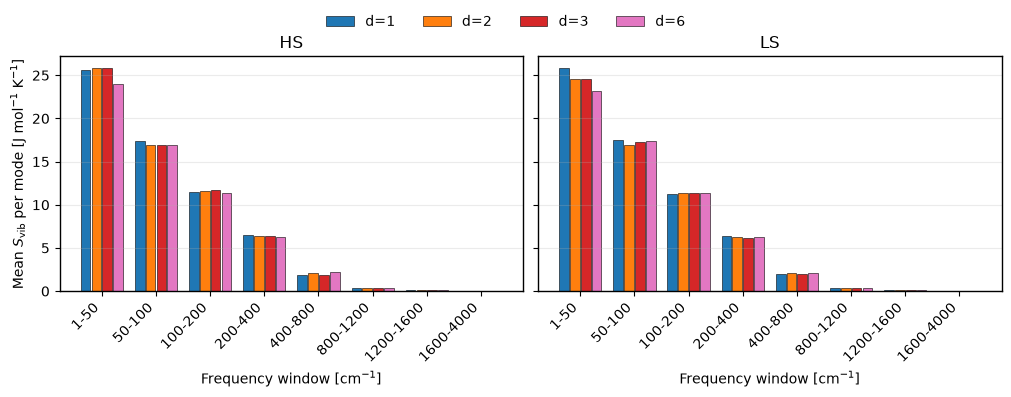

(<Figure size 1000x360 with 2 Axes>,
 array([<Axes: title={'center': 'HS'}, xlabel='Frequency window [cm$^{-1}$]', ylabel='Mean $S_{\\mathrm{vib}}$ per mode [J mol$^{-1}$ K$^{-1}$]'>,
        <Axes: title={'center': 'LS'}, xlabel='Frequency window [cm$^{-1}$]'>],
       dtype=object))

In [16]:
hs_entropy_per_mode, ordered = mean_vibrational_bin_values(homoleptic_bin_rows, 'HS_mean_S_per_mode[J·mol-1·K-1]', DENTICITIES_TO_COMPARE, bin_order)
ls_entropy_per_mode, _ = mean_vibrational_bin_values(homoleptic_bin_rows, 'LS_mean_S_per_mode[J·mol-1·K-1]', ordered, bin_order)
plot_hs_ls_frequency_profiles(hs_entropy_per_mode, ls_entropy_per_mode, ordered, bin_order, r'Mean $S_{\mathrm{vib}}$ per mode [J mol$^{-1}$ K$^{-1}$]', os.path.join(figures_path, 'vibrational_entropy_per_mode.png') if figures_path else None)

**Caption.** Mean vibrational entropy carried by one positive mode in each frequency window, resolved by denticity and spin state. This separates the entropic weight of the modes from how many modes occupy each window. Empty system--bin combinations are omitted from the corresponding average. Together with the mode-fraction plot, this shows whether the larger $\Delta S_{\mathrm{vib}}$ of a denticity originates mainly from redistribution toward softer modes or from a larger entropy contribution per mode.